shape B C H W: torch.Size([64, 1, 28, 28])
dtype: torch.float32
unique: tensor([0., 1.])


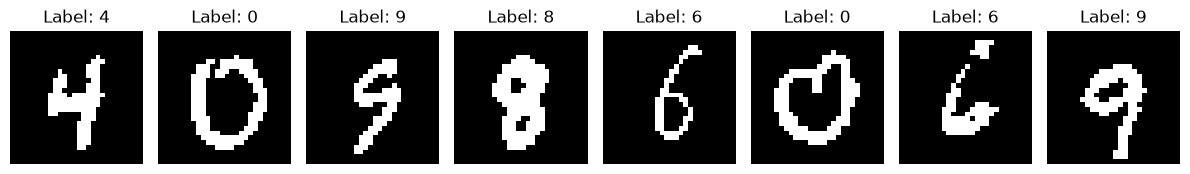

device: cuda
gpu: NVIDIA GeForce RTX 3060 Laptop GPU


In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# define flexible binarize
class FlexibleBinarize:
    def __init__(self, threshold=0.5):
        self.threshold = threshold

    def __call__(self, tensor):
        # threshold pixels to 0 or 1
        return (tensor > self.threshold).float()

# transform pipeline
transform = transforms.Compose([
    transforms.ToTensor(),
    FlexibleBinarize(threshold=0.5) # adjustable threshold
])

# load dataset; download=False since data exists
# PyTorch looks in ./data/MNIST/raw
# if you first run this code, plz set:                    download=True 
train_dataset = datasets.MNIST(root='./data', train=True, download=False, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# inspect one batch
images, labels = next(iter(train_loader))

print(f"shape B C H W: {images.shape}")
print(f"dtype: {images.dtype}")
print(f"unique: {torch.unique(images)}") # expect tensor([0., 1.])

# visualize binarization
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i in range(8):
    # images[i] is [1,28,28]; squeeze to [28,28] for plotting
    axes[i].imshow(images[i].squeeze(), cmap='gray')
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

# check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")
if device.type == 'cuda':
    print(f"gpu: {torch.cuda.get_device_name(0)}")

# FVSBN

In [58]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
import matplotlib.pyplot as plt

In [59]:
class FVSBN(nn.Module):
    def __init__(self, img_dim=28 * 28):
        super(FVSBN, self).__init__()
        self.img_dim = img_dim

        # W[i,j] dependence of pixel i on j
        self.W = nn.Parameter(torch.zeros(img_dim, img_dim))
        self.b = nn.Parameter(torch.zeros(img_dim))

        # strict lower triangular mask row i sees j<i
        # output i sees only x_<i
        self.register_buffer(
            "mask",
            torch.tril(torch.ones(img_dim, img_dim), diagonal=-1)
        )

        # small init to avoid large logits
        nn.init.normal_(self.W, mean=0.0, std=0.01)
        nn.init.zeros_(self.b)

    def forward(self, x):
        """
        x [B,784] values 0/1
        returns logits [B,784]
        logit i depends only on x_<i
        """
        # (W * mask) is strict lower triangular
        # column i of x @ (W * mask).T = sum_{j<i} x_j * W[i,j]
        logits = x @ (self.W * self.mask).T + self.b
        return logits

    @torch.no_grad()
    def generate(self, num_samples, device):
        """
        autoregressive pixel sampling
        returns [num_samples,784] 0/1 images
        """
        self.eval()
        x = torch.zeros(num_samples, self.img_dim, device=device)

        for i in range(self.img_dim):
            # pixel i depends on generated x_<i
            # use row i weights directly
            w_i = self.W[i] * self.mask[i]          # [784]
            logit_i = x @ w_i + self.b[i]           # [B]
            prob_i = torch.sigmoid(logit_i)         # [B]
            x[:, i] = torch.bernoulli(prob_i)       # sample 0/1

        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_fvsbn = FVSBN(img_dim=28 * 28).to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_fvsbn.parameters(), lr=1e-3)

print(f"params {sum(p.numel() for p in model_fvsbn.parameters()):,}")

params 615,440


training FVSBN
epoch 1/10 loss 0.2921
epoch 2/10 loss 0.1913
epoch 3/10 loss 0.1538
epoch 4/10 loss 0.1336
epoch 5/10 loss 0.1216
epoch 6/10 loss 0.1140
epoch 7/10 loss 0.1090
epoch 8/10 loss 0.1056
epoch 9/10 loss 0.1033
epoch 10/10 loss 0.1016
done in 87.46s


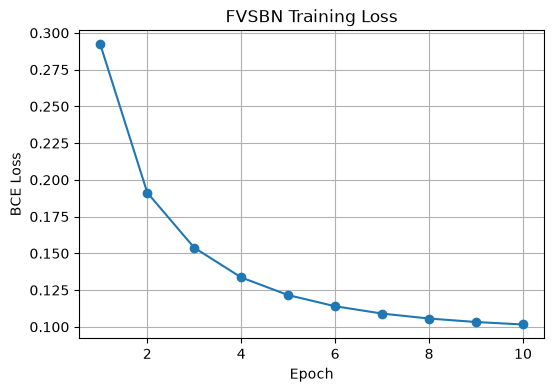

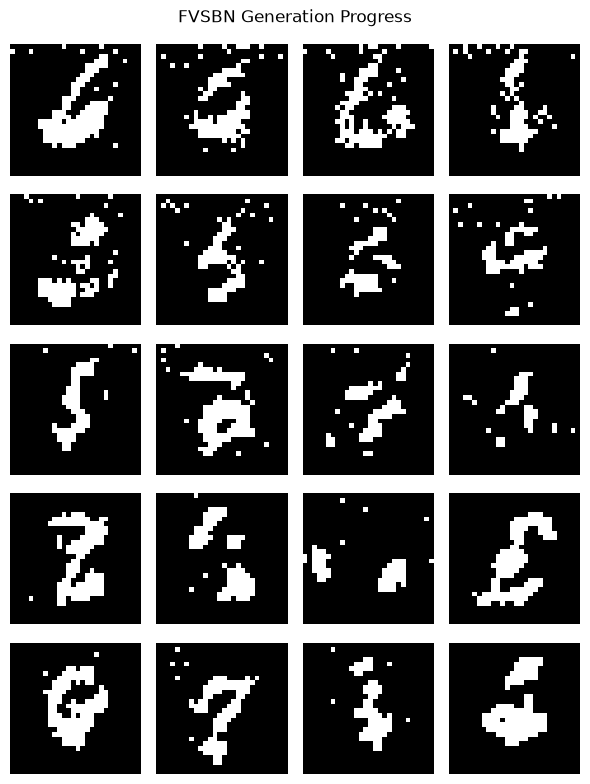

In [60]:
epochs = 10
loss_history = []
progress_images = []   # generation grid for report
progress_epochs = []

print("training FVSBN")
start_time = time.time()

for epoch in range(epochs):
    model_fvsbn.train()
    epoch_loss = 0.0

    for images, _ in train_loader:
        # [B,1,28,28] -> [B,784]
        x = images.view(images.size(0), -1).to(device)

        # forward full image; mask ensures output i sees only x_<i
        logits = model_fvsbn(x)

        # per-pixel BCE
        loss = criterion(logits, x)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(f"epoch {epoch+1}/{epochs} loss {avg_loss:.4f}")

    # save generated samples every 2 epochs
    if (epoch + 1) % 2 == 0:
        samples = model_fvsbn.generate(4, device).cpu()
        progress_images.append(samples)
        progress_epochs.append(epoch + 1)

end_time = time.time()
print(f"done in {end_time - start_time:.2f}s")

plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs + 1), loss_history, marker='o')
plt.title("FVSBN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.grid(True)
plt.show()

fig, axes = plt.subplots(len(progress_images), 4, figsize=(6, 1.6 * len(progress_images)))
if len(progress_images) == 1:
    axes = axes[None, :]

for r, (samples, ep) in enumerate(zip(progress_images, progress_epochs)):
    for c in range(4):
        img = samples[c].view(28, 28).numpy()
        axes[r, c].imshow(img, cmap='gray')
        axes[r, c].axis('off')
        if c == 0:
            axes[r, c].set_ylabel(f"Epoch {ep}", rotation=0, labelpad=30, va='center')

plt.suptitle("FVSBN Generation Progress")
plt.tight_layout()
plt.show()

inference time for 10 samples: 0.0943s


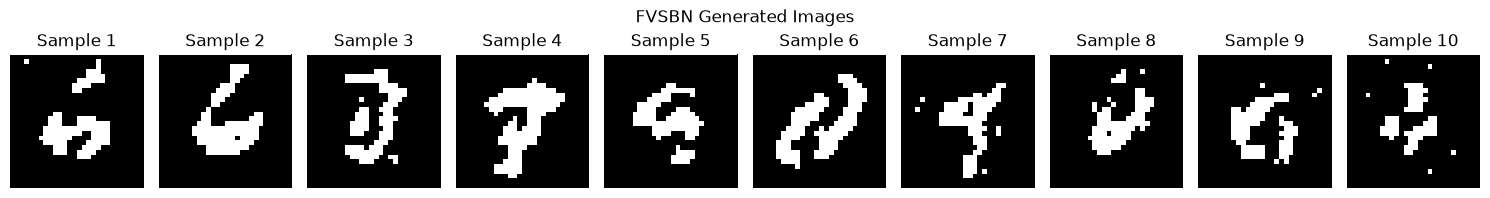

In [61]:
num_samples = 10

start_infer = time.time()
generated = model_fvsbn.generate(num_samples, device).cpu()
end_infer = time.time()

print(f"inference time for {num_samples} samples: {end_infer - start_infer:.4f}s")

fig, axes = plt.subplots(1, num_samples, figsize=(15, 2))
for i in range(num_samples):
    img = generated[i].view(28, 28).numpy()
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Sample {i+1}")
    axes[i].axis('off')
plt.suptitle("FVSBN Generated Images")
plt.tight_layout()
plt.show()

# RNN

In [62]:
class RNNGenerator(nn.Module):
    def __init__(self, input_size=1, hidden_size=128, num_layers=2):
        super(RNNGenerator, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        # input is a single pixel (0 or 1)
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        # predict next pixel probability of being 1
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x, hidden=None):
        # x shape [batch, seq_len, 1]
        out, hidden = self.rnn(x, hidden)
        out = self.fc(out)
        return out, hidden

# init
model_rnn = RNNGenerator().to(device)
optimizer_rnn = optim.Adam(model_rnn.parameters(), lr=0.001)
criterion_rnn = nn.BCEWithLogitsLoss()

training RNN
epoch 1/10 loss 0.1434
epoch 2/10 loss 0.1069
epoch 3/10 loss 0.1033
epoch 4/10 loss 0.1001
epoch 5/10 loss 0.0981
epoch 6/10 loss 0.1025
epoch 7/10 loss 0.0970
epoch 8/10 loss 0.1001
epoch 9/10 loss 0.0946
epoch 10/10 loss 0.0937
done in 102.29s


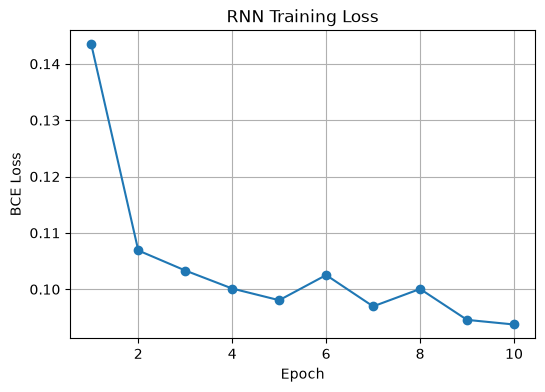

In [63]:
import time
import matplotlib.pyplot as plt

epochs_rnn = 10
loss_history_rnn = []
progress_images_rnn = []
progress_epochs_rnn = []

print("training RNN")
start_time_rnn = time.time()

for epoch in range(epochs_rnn):
    model_rnn.train()
    epoch_loss = 0.0

    for images, _ in train_loader:
        # [B,1,28,28] -> [B,784]
        x = images.view(images.size(0), -1).to(device)
        B = x.size(0)

        # start token all zeros [B,1]
        start = torch.zeros(B, 1, device=device)

        # input = [start, x_0, ..., x_782] len 784
        # target = [x_0, x_1, ..., x_783] len 784
        inputs = torch.cat([start, x[:, :-1]], dim=1).unsqueeze(-1)  # [B,784,1]
        targets = x                                                   # [B,784]

        outputs, _ = model_rnn(inputs)      # [B,784,1]
        outputs = outputs.squeeze(-1)       # [B,784]

        loss = criterion_rnn(outputs, targets)

        optimizer_rnn.zero_grad()
        loss.backward()
        optimizer_rnn.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history_rnn.append(avg_loss)
    print(f"epoch {epoch+1}/{epochs_rnn} loss {avg_loss:.4f}")

    # save generated samples every 2 epochs
    if (epoch + 1) % 2 == 0:
        model_rnn.eval()
        with torch.no_grad():
            samples = []
            current_input = torch.zeros(4, 1, 1).to(device)  # start token
            hidden = None
            for _ in range(784):
                output, hidden = model_rnn(current_input, hidden)
                prob = torch.sigmoid(output[:, -1, :])
                next_pixel = torch.bernoulli(prob)
                samples.append(next_pixel)
                current_input = next_pixel.unsqueeze(1)
            samples = torch.cat(samples, dim=1).cpu()  # [4,784]
        progress_images_rnn.append(samples)
        progress_epochs_rnn.append(epoch + 1)

end_time_rnn = time.time()
print(f"done in {end_time_rnn - start_time_rnn:.2f}s")

# loss curve
plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs_rnn + 1), loss_history_rnn, marker='o')
plt.title("RNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.grid(True)
plt.show()

inference time for 10 samples: 0.1837s


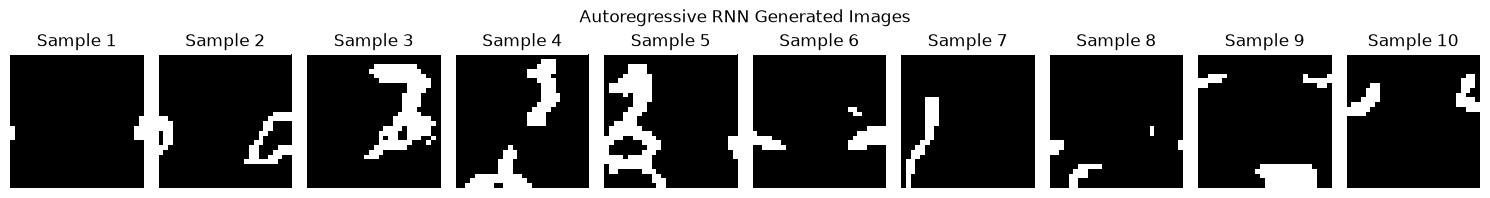

In [64]:
model_rnn.eval()

with torch.no_grad():
    num_samples = 10
    # start token all zeros [B,1,1]
    current_input = torch.zeros(num_samples, 1, 1).to(device)

    hidden = None
    generated_seq = []

    start_infer = time.time()
    for i in range(784):
        output, hidden = model_rnn(current_input, hidden)
        prob = torch.sigmoid(output[:, -1, :])       # [B,1]
        next_pixel = torch.bernoulli(prob)           # sample 0/1
        generated_seq.append(next_pixel)
        current_input = next_pixel.unsqueeze(1)      # [B,1,1]
    end_infer = time.time()

    generated_images = torch.cat(generated_seq, dim=1).cpu()  # [10,784]

print(f"inference time for {num_samples} samples: {end_infer - start_infer:.4f}s")

fig, axes = plt.subplots(1, num_samples, figsize=(15, 2))
for i in range(num_samples):
    img = generated_images[i].view(28, 28).numpy()
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Sample {i+1}")
    axes[i].axis('off')
plt.suptitle("Autoregressive RNN Generated Images")
plt.tight_layout()
plt.show()

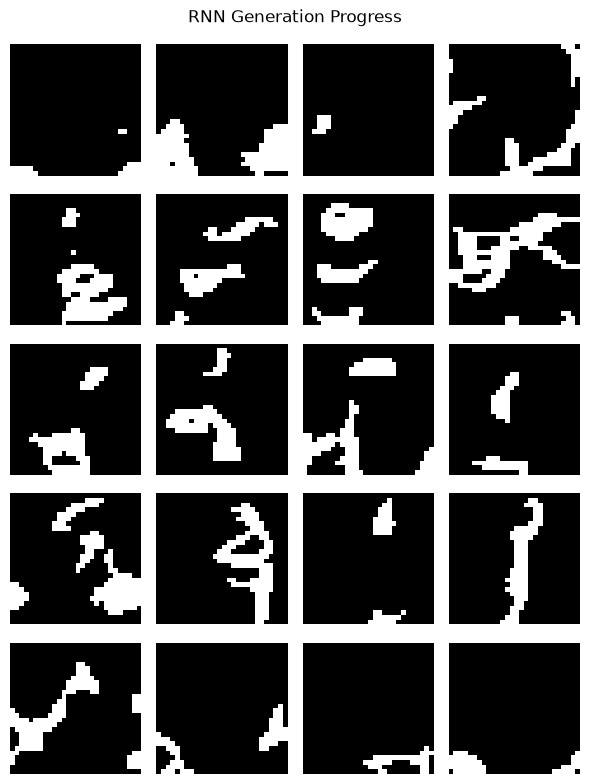

In [65]:
fig, axes = plt.subplots(len(progress_images_rnn), 4, figsize=(6, 1.6 * len(progress_images_rnn)))
if len(progress_images_rnn) == 1:
    axes = axes[None, :]

for r, (samples, ep) in enumerate(zip(progress_images_rnn, progress_epochs_rnn)):
    for c in range(4):
        axes[r, c].imshow(samples[c].view(28, 28).numpy(), cmap='gray')
        axes[r, c].axis('off')
        if c == 0:
            axes[r, c].set_ylabel(f"Epoch {ep}", rotation=0, labelpad=30, va='center')

plt.suptitle("RNN Generation Progress")
plt.tight_layout()
plt.show()

# Comparison RNN/LSTM/GRU

In [66]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
import matplotlib.pyplot as plt

# unified autoregressive model, switch via rnn_type
class ARGenerator(nn.Module):
    def __init__(self, rnn_type='LSTM', input_size=1, hidden_size=256, num_layers=2):
        super(ARGenerator, self).__init__()
        self.rnn_type = rnn_type
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        # pick RNN layer by type
        if rnn_type == 'RNN':
            self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        elif rnn_type == 'LSTM':
            self.rnn = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        elif rnn_type == 'GRU':
            self.rnn = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        else:
            raise ValueError("rnn_type must be 'RNN', 'LSTM', or 'GRU'")
            
        # output logits for next pixel prob of being 1
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x, hidden=None):
        # x shape [B, seq_len, 1]
        out, hidden = self.rnn(x, hidden)
        out = self.fc(out)
        return out, hidden

In [67]:
def train_ar_model(model_name, model, epochs=15):
    print(f"\nstart training {model_name}")
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    loss_history = []
    progress_images = []
    progress_epochs = []
    
    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        
        for images, _ in train_loader:
            x = images.view(images.size(0), -1).to(device) # [B,784]
            B = x.size(0)
            
            # teacher forcing: input = [start_token, x_0, ..., x_782]
            start = torch.zeros(B, 1, device=device)
            inputs = torch.cat([start, x[:, :-1]], dim=1).unsqueeze(-1) # [B,784,1]
            targets = x # [B,784]
            
            # hidden None -> PyTorch inits to zeros
            outputs, _ = model(inputs, None) 
            outputs = outputs.squeeze(-1) # [B,784]
            
            loss = criterion(outputs, targets)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            
        avg_loss = epoch_loss / len(train_loader)
        loss_history.append(avg_loss)
        print(f"epoch {epoch+1}/{epochs} loss {avg_loss:.4f}")
        
        # save generated samples every 3 epochs for report
        if (epoch + 1) % 3 == 0 or (epoch + 1) == epochs:
            model.eval()
            with torch.no_grad():
                samples = []
                current_input = torch.zeros(4, 1, 1).to(device) # start token
                hidden = None
                for _ in range(784):
                    output, hidden = model(current_input, hidden)
                    prob = torch.sigmoid(output[:, -1, :])
                    next_pixel = torch.bernoulli(prob)
                    samples.append(next_pixel)
                    current_input = next_pixel.unsqueeze(1)
                samples = torch.cat(samples, dim=1).cpu()
            progress_images.append(samples)
            progress_epochs.append(epoch + 1)
            
    end_time = time.time()
    print(f"{model_name} done in {end_time - start_time:.2f}s")
    return loss_history, progress_images, progress_epochs

In [68]:
epochs_ar = 10

results = {}

In [69]:
# RNN
model_rnn = ARGenerator('RNN', hidden_size=256, num_layers=2).to(device)
loss_rnn, prog_rnn, ep_rnn = train_ar_model("Vanilla RNN", model_rnn, epochs_ar)
results['RNN'] = (loss_rnn, prog_rnn, ep_rnn)


start training Vanilla RNN
epoch 1/10 loss 0.2164
epoch 2/10 loss 0.2055
epoch 3/10 loss 0.2093
epoch 4/10 loss 0.2218
epoch 5/10 loss 0.2214
epoch 6/10 loss 0.2092
epoch 7/10 loss 0.2090
epoch 8/10 loss 0.2081
epoch 9/10 loss 0.2159
epoch 10/10 loss 0.2090
Vanilla RNN done in 290.41s


In [70]:
# LSTM
model_lstm = ARGenerator('LSTM', hidden_size=256, num_layers=2).to(device)
loss_lstm, prog_lstm, ep_lstm = train_ar_model("LSTM", model_lstm, epochs_ar)
results['LSTM'] = (loss_lstm, prog_lstm, ep_lstm)


start training LSTM
epoch 1/10 loss 0.1437
epoch 2/10 loss 0.0932
epoch 3/10 loss 0.0869
epoch 4/10 loss 0.0820
epoch 5/10 loss 0.0796
epoch 6/10 loss 0.0778
epoch 7/10 loss 0.0767
epoch 8/10 loss 0.0759
epoch 9/10 loss 0.0754
epoch 10/10 loss 0.0747
LSTM done in 699.89s


In [71]:
# GRU
model_gru = ARGenerator('GRU', hidden_size=256, num_layers=2).to(device)
loss_gru, prog_gru, ep_gru = train_ar_model("GRU", model_gru, epochs_ar)
results['GRU'] = (loss_gru, prog_gru, ep_gru)


start training GRU
epoch 1/10 loss 0.1456
epoch 2/10 loss 0.0942
epoch 3/10 loss 0.0887
epoch 4/10 loss 0.0856
epoch 5/10 loss 0.0826
epoch 6/10 loss 0.0805
epoch 7/10 loss 0.0791
epoch 8/10 loss 0.0781
epoch 9/10 loss 0.0774
epoch 10/10 loss 0.0768
GRU done in 675.89s


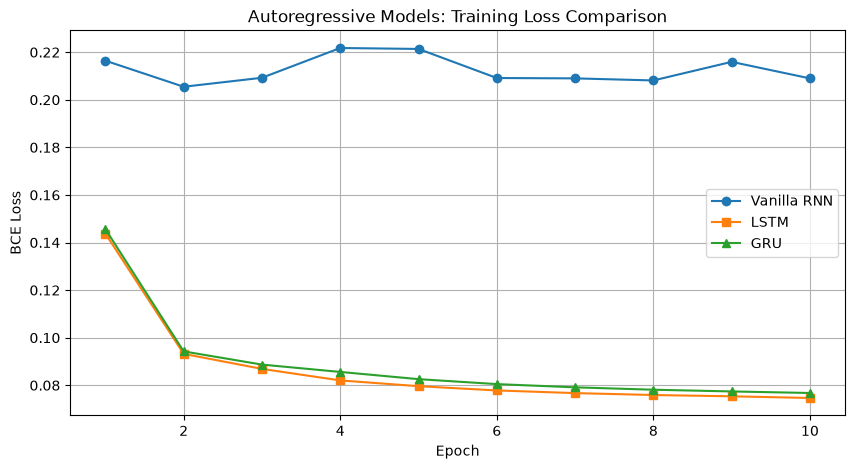

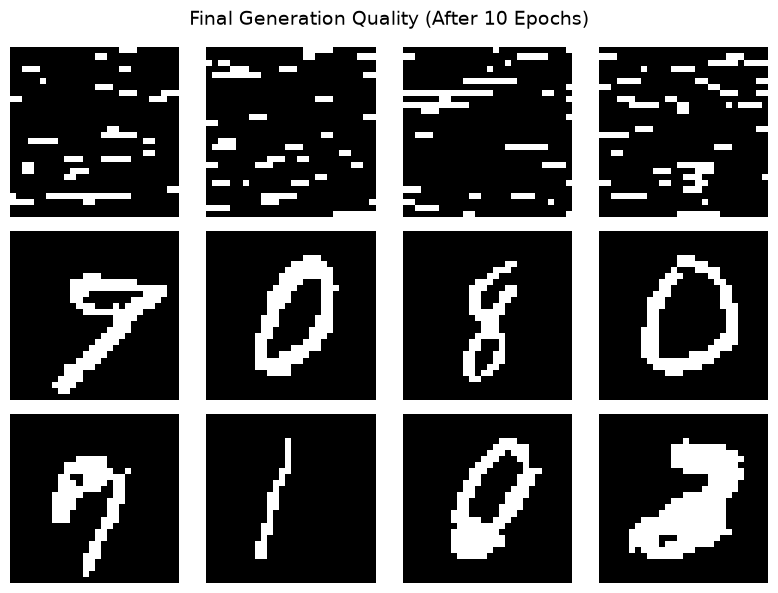


inference time test
LSTM inference time for 10 samples: 0.2046s


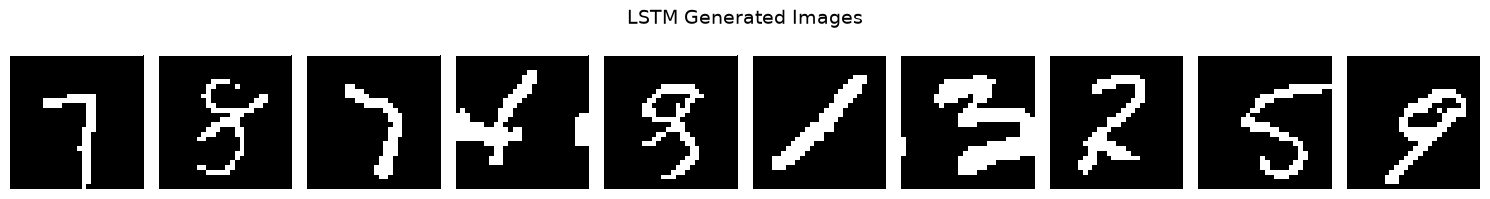

In [72]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs_ar + 1), results['RNN'][0], marker='o', label='Vanilla RNN')
plt.plot(range(1, epochs_ar + 1), results['LSTM'][0], marker='s', label='LSTM')
plt.plot(range(1, epochs_ar + 1), results['GRU'][0], marker='^', label='GRU')
plt.title("Autoregressive Models: Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(len(results), 4, figsize=(8, 2 * len(results)))
model_names = list(results.keys())

for r, name in enumerate(model_names):
    _, imgs, _ = results[name]
    samples = imgs[-1] # last epoch samples
    for c in range(4):
        axes[r, c].imshow(samples[c].view(28, 28).numpy(), cmap='gray')
        axes[r, c].axis('off')
        if c == 0:
            axes[r, c].set_ylabel(name, rotation=0, labelpad=40, va='center', fontsize=12)

plt.suptitle("Final Generation Quality (After 10 Epochs)", fontsize=14)
plt.tight_layout()
plt.show()

print("\ninference time test")
def test_inference_time(model, num_samples=10):
    model.eval()
    with torch.no_grad():
        if device.type == 'cuda': torch.cuda.synchronize()
        start = time.time()
        
        current_input = torch.zeros(num_samples, 1, 1).to(device)
        hidden = None
        generated_seq = []
        for _ in range(784):
            output, hidden = model(current_input, hidden)
            prob = torch.sigmoid(output[:, -1, :])
            next_pixel = torch.bernoulli(prob)
            generated_seq.append(next_pixel)
            current_input = next_pixel.unsqueeze(1)
            
        if device.type == 'cuda': torch.cuda.synchronize()
        end = time.time()
        
    return end - start, torch.cat(generated_seq, dim=1).cpu()

# test LSTM (best performer)
time_lstm, gen_lstm = test_inference_time(model_lstm, 10)
print(f"LSTM inference time for 10 samples: {time_lstm:.4f}s")

# visualize 10 LSTM samples
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    axes[i].imshow(gen_lstm[i].view(28, 28).numpy(), cmap='gray')
    axes[i].axis('off')
plt.suptitle("LSTM Generated Images", fontsize=14)
plt.tight_layout()
plt.show()

# GAN

In [73]:
transform_gan = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) 
])

train_dataset_gan = datasets.MNIST(root='./data', train=True, download=False, transform=transform_gan)
train_loader_gan = DataLoader(train_dataset_gan, batch_size=128, shuffle=True)

In [74]:
import torch.nn as nn

# generator
class Generator(nn.Module):
    def __init__(self, latent_dim=64):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            # input [batch,64]
            nn.Linear(latent_dim, 128 * 7 * 7),
            nn.BatchNorm1d(128 * 7 * 7),
            nn.ReLU(True),
            nn.Unflatten(1, (128, 7, 7)), # -> [batch,128,7,7]
            
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1), # -> [batch,64,14,14]
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1), # -> [batch,1,28,28]
            nn.Tanh() # input normalized to [-1,1], so use Tanh
        )

    def forward(self, x):
        return self.main(x)

# discriminator
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            # input [batch,1,28,28]
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1), # -> [batch,64,14,14]
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # -> [batch,128,7,7]
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.5),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            #nn.Sigmoid() # prob of real 0 to 1
        )

    def forward(self, x):
        if self.training:
            noise = torch.randn_like(x) * 0.05
            x = x + noise
        return self.main(x)

In [75]:
import time
import matplotlib.pyplot as plt

latent_dim = 64
netG_gan = Generator(latent_dim).to(device)
netD_gan = Discriminator().to(device)

optimizerD_gan = optim.Adam(netD_gan.parameters(), lr=0.0001, betas=(0.5, 0.999))
optimizerG_gan = optim.Adam(netG_gan.parameters(), lr=0.0003, betas=(0.5, 0.999))

criterion_gan = nn.BCEWithLogitsLoss()

epochs_gan = 15
losses_D_gan = []
losses_G_gan = []
progress_images_gan = []
progress_epochs_gan = []

# fixed noise to track same latents over training
fixed_noise_gan = torch.randn(4, latent_dim).to(device)

print("training GAN")
start_time_gan = time.time()

for epoch in range(epochs_gan):
    netG_gan.train()
    netD_gan.train()

    epoch_loss_D = 0.0
    epoch_loss_G = 0.0

    for i, (real_imgs, _) in enumerate(train_loader_gan):
        batch_size = real_imgs.size(0)
        real_imgs = real_imgs.to(device)

        # train discriminator
        netD_gan.zero_grad()

        # real images, label smoothing 0.9
        real_targets = torch.full((batch_size, 1), 0.9, device=device)
        output_real = netD_gan(real_imgs)
        lossD_real = criterion_gan(output_real, real_targets)

        # fake images
        noise = torch.randn(batch_size, latent_dim).to(device)
        fake_imgs = netG_gan(noise)
        fake_targets = torch.full((batch_size, 1), 0.1, device=device)
        output_fake = netD_gan(fake_imgs.detach())
        lossD_fake = criterion_gan(output_fake, fake_targets)

        lossD = lossD_real + lossD_fake
        lossD.backward()
        optimizerD_gan.step()

        # train generator
        netG_gan.zero_grad()
        output_fake_for_G = netD_gan(fake_imgs)
        lossG = criterion_gan(output_fake_for_G, real_targets)  # want real
        lossG.backward()
        optimizerG_gan.step()

        epoch_loss_D += lossD.item()
        epoch_loss_G += lossG.item()

    avg_loss_D = epoch_loss_D / len(train_loader_gan)
    avg_loss_G = epoch_loss_G / len(train_loader_gan)
    losses_D_gan.append(avg_loss_D)
    losses_G_gan.append(avg_loss_G)

    print(f"epoch {epoch+1}/{epochs_gan} lossD {avg_loss_D:.4f} lossG {avg_loss_G:.4f}")

    # generate 4 images from fixed noise every 3 epochs
    if (epoch + 1) % 3 == 0:
        netG_gan.eval()
        with torch.no_grad():
            samples = netG_gan(fixed_noise_gan).cpu()
            samples = (samples + 1) / 2.0  # [-1,1] -> [0,1]
        progress_images_gan.append(samples)
        progress_epochs_gan.append(epoch + 1)

end_time_gan = time.time()
print(f"\nGAN done in {end_time_gan - start_time_gan:.2f}s")

training GAN
epoch 1/15 lossD 1.0332 lossG 1.1347
epoch 2/15 lossD 0.9295 lossG 1.3512
epoch 3/15 lossD 0.9800 lossG 1.3298
epoch 4/15 lossD 1.0361 lossG 1.2464
epoch 5/15 lossD 1.0597 lossG 1.2169
epoch 6/15 lossD 1.0752 lossG 1.2130
epoch 7/15 lossD 1.0828 lossG 1.2021
epoch 8/15 lossD 1.0871 lossG 1.1990
epoch 9/15 lossD 1.0899 lossG 1.2018
epoch 10/15 lossD 1.0967 lossG 1.1978
epoch 11/15 lossD 1.0977 lossG 1.1980
epoch 12/15 lossD 1.1026 lossG 1.1974
epoch 13/15 lossD 1.1065 lossG 1.1917
epoch 14/15 lossD 1.1074 lossG 1.1859
epoch 15/15 lossD 1.1106 lossG 1.1862

GAN done in 191.79s


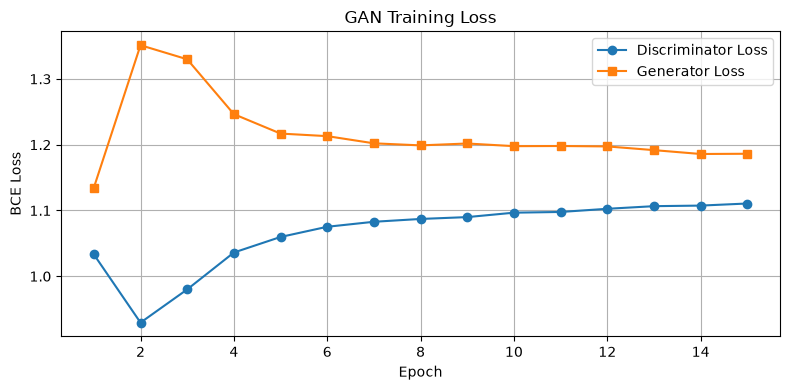

In [76]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs_gan + 1), losses_D_gan, marker='o', label='Discriminator Loss')
plt.plot(range(1, epochs_gan + 1), losses_G_gan, marker='s', label='Generator Loss')
plt.title("GAN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

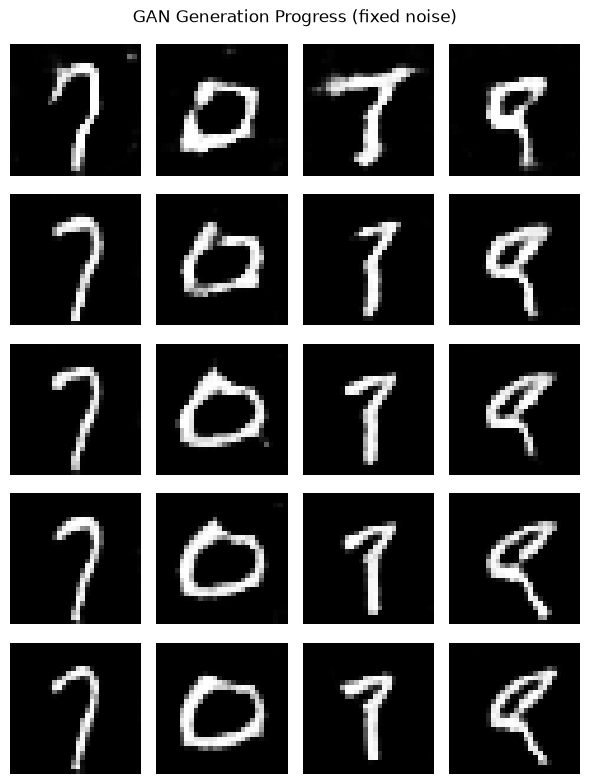

In [77]:
num_stages = len(progress_images_gan)
fig, axes = plt.subplots(num_stages, 4, figsize=(6, 1.6 * num_stages))
if num_stages == 1:
    axes = axes[None, :]

for r, (samples, ep) in enumerate(zip(progress_images_gan, progress_epochs_gan)):
    for c in range(4):
        img = samples[c].squeeze().numpy()
        axes[r, c].imshow(img, cmap='gray')
        axes[r, c].axis('off')
        if c == 0:
            axes[r, c].set_ylabel(f"Epoch {ep}", rotation=0, labelpad=30, va='center')

plt.suptitle("GAN Generation Progress (fixed noise)")
plt.tight_layout()
plt.show()

GAN inference time for 100 samples: 0.0007s
avg per sample: 0.007 ms


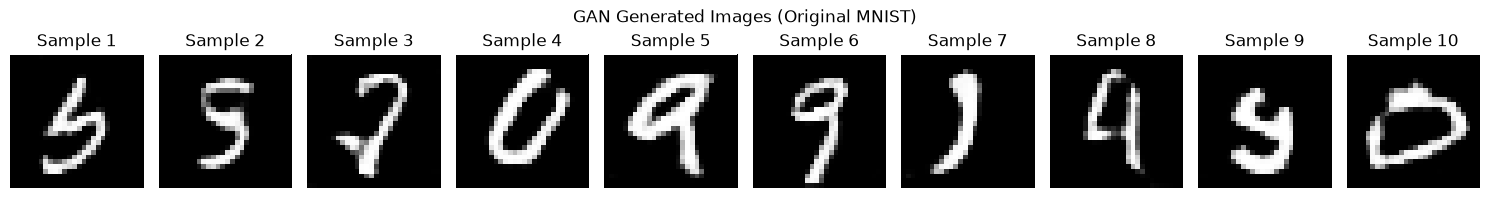

In [78]:
netG_gan.eval()
with torch.no_grad():
    # time 100-sample inference
    test_noise = torch.randn(100, latent_dim).to(device)
    start_infer = time.time()
    _ = netG_gan(test_noise)
    end_infer = time.time()
    print(f"GAN inference time for 100 samples: {end_infer - start_infer:.4f}s")
    print(f"avg per sample: {(end_infer - start_infer) / 100 * 1000:.3f} ms")

    # show 10 samples
    noise = torch.randn(10, latent_dim).to(device)
    fake_imgs = netG_gan(noise).cpu()
    fake_imgs = (fake_imgs + 1) / 2.0

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    axes[i].imshow(fake_imgs[i].squeeze().numpy(), cmap='gray')
    axes[i].set_title(f"Sample {i+1}")
    axes[i].axis('off')
plt.suptitle("GAN Generated Images (Original MNIST)")
plt.tight_layout()
plt.show()

In [79]:
import time
import torch

netG_gan.eval()
num_samples = 100
test_noise = torch.randn(num_samples, latent_dim).to(device)

# Warm-up
with torch.no_grad():
    _ = netG_gan(test_noise)

if device.type == 'cuda':
    torch.cuda.synchronize()
start_time = time.time()

with torch.no_grad():
    _ = netG_gan(test_noise)

if device.type == 'cuda':
    torch.cuda.synchronize()
end_time = time.time()

print(f"Strict GAN inference time for {num_samples} samples: {end_time - start_time:.4f} s")
print(f"Average time per sample: {(end_time - start_time) / num_samples * 1000:.3f} ms")

Strict GAN inference time for 100 samples: 0.0011 s
Average time per sample: 0.011 ms


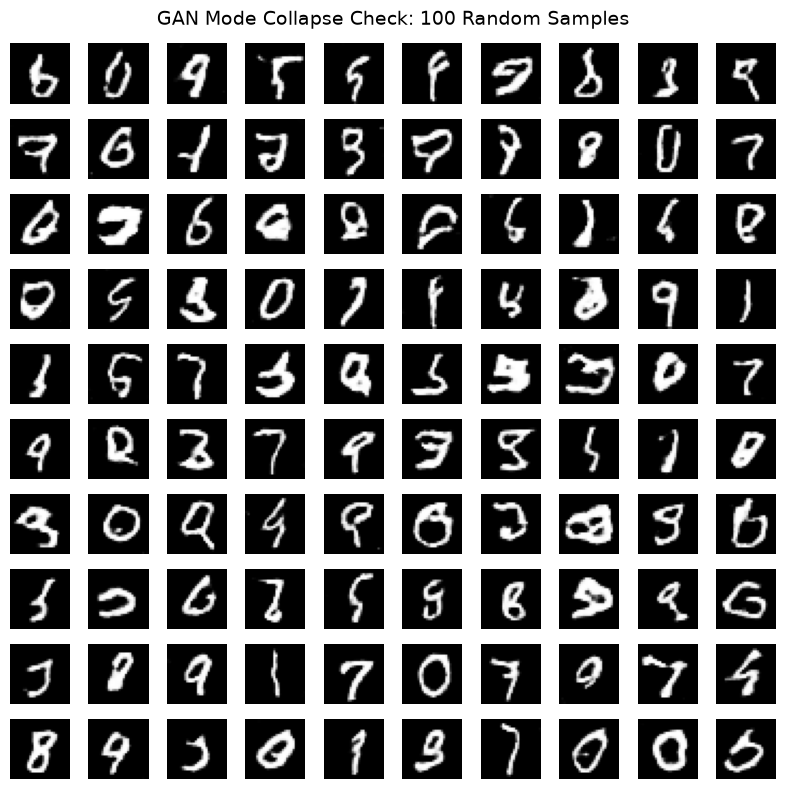

In [80]:
import matplotlib.pyplot as plt

netG_gan.eval()
with torch.no_grad():
    noise = torch.randn(100, latent_dim).to(device)
    fake_imgs = netG_gan(noise).cpu()
    fake_imgs = (fake_imgs + 1) / 2.0

fig, axes = plt.subplots(10, 10, figsize=(8, 8))
for i in range(10):
    for j in range(10):
        idx = i * 10 + j
        axes[i, j].imshow(fake_imgs[idx].squeeze().numpy(), cmap='gray')
        axes[i, j].axis('off')

plt.suptitle("GAN Mode Collapse Check: 100 Random Samples", fontsize=14)
plt.tight_layout()
plt.show()

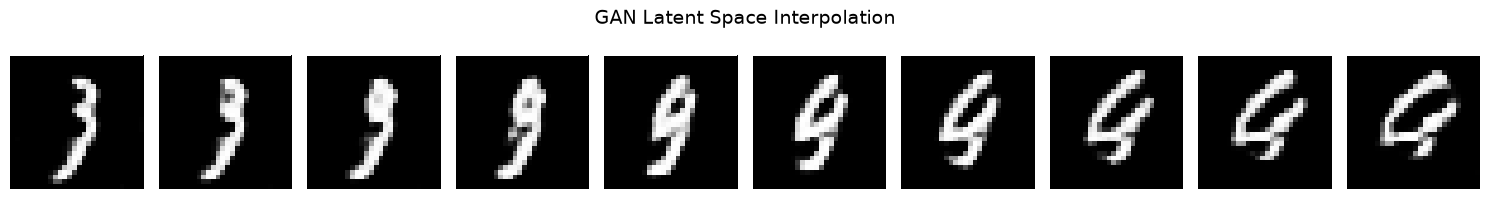

In [81]:
import matplotlib.pyplot as plt

netG_gan.eval()
with torch.no_grad():
    z1 = torch.randn(1, latent_dim).to(device)
    z2 = torch.randn(1, latent_dim).to(device)
    
    alphas = torch.linspace(0, 1, 10, device=device).view(-1, 1)
    z_interp = z1 * (1 - alphas) + z2 * alphas
    
    interp_imgs = netG_gan(z_interp).cpu()
    interp_imgs = (interp_imgs + 1) / 2.0

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    axes[i].imshow(interp_imgs[i].squeeze().numpy(), cmap='gray')
    axes[i].axis('off')

plt.suptitle("GAN Latent Space Interpolation", fontsize=14)
plt.tight_layout()
plt.show()

# cGAN

In [103]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
from tqdm.notebook import tqdm

class cGenerator(nn.Module):
    def __init__(self, latent_dim=64, num_classes=10, embed_dim=10):
        super(cGenerator, self).__init__()
        # embed labels (0-9) into 10-dim vectors
        self.embed = nn.Embedding(num_classes, embed_dim)
        
        self.main = nn.Sequential(
            # input dim = noise + label = 64 + 10 = 74
            nn.Linear(latent_dim + embed_dim, 128 * 7 * 7),
            nn.BatchNorm1d(128 * 7 * 7),
            nn.ReLU(True),
            nn.Unflatten(1, (128, 7, 7)),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        # embed labels and concat with noise
        label_embed = self.embed(labels)
        x = torch.cat([noise, label_embed], dim=1) 
        return self.main(x)

In [104]:

class cDiscriminator(nn.Module):
    def __init__(self, num_classes=10, embed_dim=10):
        super(cDiscriminator, self).__init__()
        self.embed = nn.Embedding(num_classes, embed_dim)
        
        self.main = nn.Sequential(
            # input 1 channel, concat label -> 1 + 10 = 11 channels
            nn.Conv2d(1 + embed_dim, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            #nn.Sigmoid()
        )

    def forward(self, img, labels):
        # label -> [batch,embed_dim,1,1] then expand to [batch,embed_dim,28,28]
        label_embed = self.embed(labels)
        label_embed = label_embed.view(-1, 10, 1, 1).expand(-1, -1, 28, 28)
        # concat along channel dim -> [batch,11,28,28]
        x = torch.cat([img, label_embed], dim=1) 
        return self.main(x)

In [105]:
# basic params
latent_dim = 64
num_classes = 10
epochs_gan = 20

# instantiate models
cnetG = cGenerator(latent_dim=latent_dim, num_classes=num_classes).to(device)
cnetD = cDiscriminator(num_classes=num_classes).to(device)

# optimizers (keep TTUR: slower D to prevent D dominating G)
optimizerD = optim.Adam(cnetD.parameters(), lr=0.0001, betas=(0.5, 0.999))
optimizerG = optim.Adam(cnetG.parameters(), lr=0.0003, betas=(0.5, 0.999))

criterion = nn.BCEWithLogitsLoss()

# loss history for plotting
losses_D = []
losses_G = []


In [106]:
print("training cGAN")
start_time_gan = time.time()

for epoch in range(epochs_gan):
    epoch_loss_D = 0.0
    epoch_loss_G = 0.0
    
    for i, (real_imgs, real_labels_batch) in enumerate(train_loader_gan):
        batch_size = real_imgs.size(0)
        real_imgs = real_imgs.to(device)
        real_labels_batch = real_labels_batch.to(device) # real image labels
        
        cnetD.zero_grad()
        
        # label smoothing: real target 0.9 not 1.0
        real_targets = torch.full((batch_size, 1), 0.9, device=device)
        
        # real forward (image + label)
        output_real = cnetD(real_imgs, real_labels_batch)
        lossD_real = criterion(output_real, real_targets)
        
        # generate fake (noise + random fake labels)
        noise = torch.randn(batch_size, latent_dim).to(device)
        fake_labels_batch = torch.randint(0, num_classes, (batch_size,), device=device)
        fake_imgs = cnetG(noise, fake_labels_batch)
        
        # fake forward (.detach() blocks G grad)
        fake_targets = torch.full((batch_size, 1), 0.1, device=device)
        output_fake = cnetD(fake_imgs.detach(), fake_labels_batch)
        lossD_fake = criterion(output_fake, fake_targets)
        
        # update D
        lossD = lossD_real + lossD_fake
        lossD.backward()
        optimizerD.step()
        
        cnetG.zero_grad()
        
        # G wants to fool D, so target 0.9 (real)
        output_fake_for_G = cnetD(fake_imgs, fake_labels_batch)
        lossG = criterion(output_fake_for_G, real_targets)
        
        # update G
        lossG.backward()
        optimizerG.step()
        
        # record loss
        epoch_loss_D += lossD.item()
        epoch_loss_G += lossG.item()
        
    # mean loss per epoch
    avg_loss_D = epoch_loss_D / len(train_loader_gan)
    avg_loss_G = epoch_loss_G / len(train_loader_gan)
    losses_D.append(avg_loss_D)
    losses_G.append(avg_loss_G)
    
    # print once per epoch
    print(f"epoch {epoch+1}/{epochs_gan} lossD {avg_loss_D:.4f} lossG {avg_loss_G:.4f}")

print(f"\ncGAN done in {time.time() - start_time_gan:.2f}s")

training cGAN
epoch 1/20 lossD 1.1348 lossG 1.0129
epoch 2/20 lossD 1.3014 lossG 0.8022
epoch 3/20 lossD 1.2846 lossG 0.8174
epoch 4/20 lossD 1.2870 lossG 0.8336
epoch 5/20 lossD 1.3150 lossG 0.8029
epoch 6/20 lossD 1.3389 lossG 0.7822
epoch 7/20 lossD 1.3428 lossG 0.7814
epoch 8/20 lossD 1.3426 lossG 0.7812
epoch 9/20 lossD 1.3429 lossG 0.7824
epoch 10/20 lossD 1.3459 lossG 0.7805
epoch 11/20 lossD 1.3615 lossG 0.7604
epoch 12/20 lossD 1.3420 lossG 0.7746
epoch 13/20 lossD 1.3503 lossG 0.7776
epoch 14/20 lossD 1.3361 lossG 0.7903
epoch 15/20 lossD 1.3453 lossG 0.7803
epoch 16/20 lossD 1.3387 lossG 0.7821
epoch 17/20 lossD 1.3465 lossG 0.7821
epoch 18/20 lossD 1.3522 lossG 0.7675
epoch 19/20 lossD 1.3453 lossG 0.7746
epoch 20/20 lossD 1.3406 lossG 0.7850

cGAN done in 254.85s


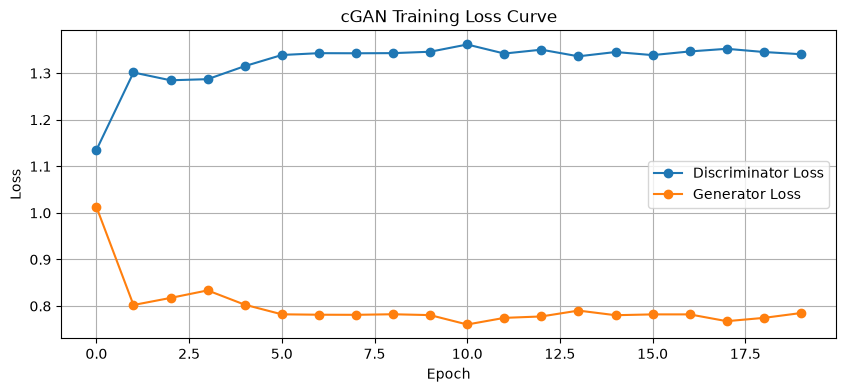

In [107]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(losses_D, label='Discriminator Loss', marker='o')
plt.plot(losses_G, label='Generator Loss', marker='o')
plt.title("cGAN Training Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

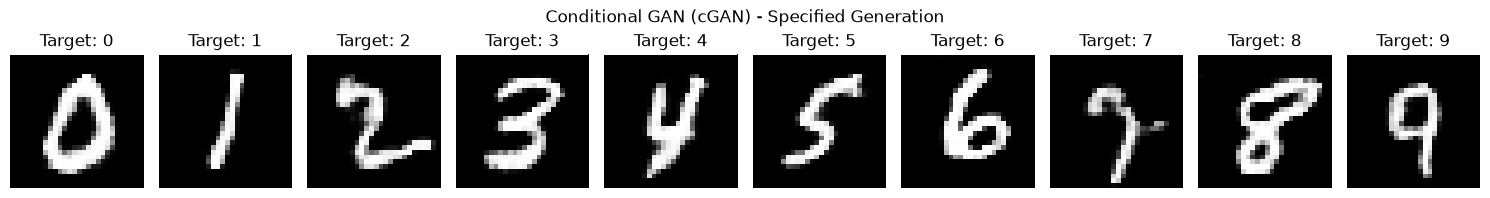

In [109]:
cnetG.eval()
with torch.no_grad():
    num_samples = 10
    # random noise
    noise = torch.randn(num_samples, latent_dim).to(device)
    
    # specify digits 0-9 to generate
    specified_labels = torch.arange(0, 10).to(device) 
    
    # generate images
    fake_imgs = cnetG(noise, specified_labels).cpu()
    
    # denormalize [-1,1] -> [0,1] for display
    fake_imgs = (fake_imgs + 1) / 2.0 

    fig, axes = plt.subplots(1, 10, figsize=(15, 2))
    for i in range(10):
        img = fake_imgs[i].squeeze()
        axes[i].imshow(img, cmap='gray')
        # show specified label in title
        axes[i].set_title(f"Target: {specified_labels[i].item()}") 
        axes[i].axis('off')
    
    plt.suptitle("Conditional GAN (cGAN) - Specified Generation")
    plt.tight_layout()
    plt.show()